In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer

In [2]:
df = pd.read_csv('../data/inverted.txt')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
target = "converted"
categorical = [c for c in df.columns if df[c].dtype == "object" or str(df[c].dtype) == "str"]
numerical = [c for c in df.columns if c not in categorical and c != target]


print("Categorical columns:", categorical)
print("Numerical columns:", numerical)

Categorical columns: ['lead_source', 'industry', 'employment_status', 'location']
Numerical columns: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [6]:
for c in categorical:
    df[c] = df[c].fillna("NA")
    
for c in numerical:
    df[c] = df[c].fillna(0.0)

In [7]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [67]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train[target].values
y_val = df_val[target].values
print("Split sizes:", len(df_train), len(df_val), len(df_test), "\n")

Split sizes: 3000 1000 1000 



In [68]:
features = categorical + numerical

In [69]:
def train(df_tr, y_tr, C=1.0):

    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient="records"))

    model = LogisticRegression(
        solver="liblinear", 
        C=C, 
        max_iter=1000
    )
    model.fit(X, y_tr)

    return dv, model


def predict(dv, model, df_x):

    X = dv.transform(df_x[features].to_dict(orient="records"))
    
    return model.predict_proba(X)[:, 1]

In [70]:

vars = ["lead_score", "number_of_courses_viewed", "interaction_count", "annual_income"]

rascore = {}

print("-" * 38)
print("-"*16 + " auc " + "-"*16)
print("-" * 38)
for c in vars:
    AUC = roc_auc_score(y_train, df_train[c])

    if AUC < 0.5:
        AUC = roc_auc_score(y_train, -df_train[c])

    rascore[c] = (AUC)

    print(f"  {c:25s} {AUC:.4f}")

print(rascore)
print(f"---> hightest: {max(rascore, key=rascore.get)}")

--------------------------------------
---------------- auc ----------------
--------------------------------------
  lead_score                0.7882
  number_of_courses_viewed  0.7230
  interaction_count         0.7649
  annual_income             0.6082
{'lead_score': 0.7882254810906102, 'number_of_courses_viewed': 0.7229894623989618, 'interaction_count': 0.7649203047563227, 'annual_income': 0.6081977776250831}
---> hightest: lead_score


In [71]:
# vars = ["lead_score", "number_of_courses_viewed", "interaction_count", "annual_income"]

# r_a_score = {}
# for c in vars:
#     auc = roc_auc_score(y_train, df_train[c])
#     if auc < 0.5:
#         auc = roc_auc_score(y_train, -df_train[c])
#     r_a_score[c] = auc
#     print(f"  {c:28s} {auc:.4f}")
# print("  -> highest:", max(r_a_score, key=r_a_score .get), "\n")

In [72]:
dv, model = train(df_train, y_train, C=1.0)

y_pred = predict(dv, model, df_val)

print(f"validation AUC = {roc_auc_score(y_val, y_pred):.3f}")

validation AUC = 0.732


In [73]:
np.arange(0.0, 1.01, 0.01)

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [76]:
y_pred

array([0.54472295, 0.79005195, 0.50977888, 0.52913938, 0.82072019,
       0.54245978, 0.50178713, 0.54698387, 0.82553293, 0.40583733,
       0.91301563, 0.33581814, 0.30789865, 0.42704779, 0.62192278,
       0.53665458, 0.41931919, 0.8408734 , 0.79969125, 0.61790114,
       0.61625178, 0.68059917, 0.85605897, 0.80784866, 0.62046001,
       0.45970706, 0.54556701, 0.41221376, 0.72714009, 0.46812074,
       0.77222177, 0.79043875, 0.61433884, 0.78549747, 0.49753408,
       0.66077272, 0.69804752, 0.76896541, 0.65657489, 0.64127891,
       0.665091  , 0.57942805, 0.67830933, 0.61186093, 0.86890227,
       0.41469666, 0.84130124, 0.74229353, 0.68028534, 0.71891427,
       0.86417925, 0.64043353, 0.54246981, 0.70225149, 0.27894887,
       0.70826476, 0.62310694, 0.47781746, 0.37914009, 0.69936028,
       0.52032854, 0.69977689, 0.75148934, 0.58087484, 0.47001787,
       0.56863469, 0.91297179, 0.79972019, 0.82206539, 0.36140186,
       0.66132383, 0.52330043, 0.79295458, 0.72068066, 0.71234

In [80]:
for t in np.arange(0.0, 1.01, 0.01):
    pred_pos = y_pred >= t
    pred_neg = y_pred < t
    print(pred_pos[:5])
    print(pred_neg[:5])
    print(~pred_pos[:5])
    print()

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True]
[False False False False False]
[False False False False False]

[ True  True  True  True  True

In [111]:
rows = []

for t in np.linspace(0, 1, 101):

    pred_pos = y_pred >= t
    actual_positive = y_val == 1
    actual_negative = y_val == 0

    tp = (pred_pos & actual_positive).sum()
    fp = (pred_pos & actual_negative).sum()
    fn = (~pred_pos & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    
    rows.append((round(t, 2), p, r, f1))

scores = pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1"])
scores

,threshold,precision,recall,f1
0,0.00,0.586,1.000000,0.738966
1,0.01,0.586,1.000000,0.738966
2,0.02,0.586,1.000000,0.738966
3,0.03,0.586,1.000000,0.738966
4,0.04,0.586,1.000000,0.738966
...,...,...,...,...
96,0.96,1.000,0.001706,0.003407
97,0.97,0.000,0.000000,0.000000
98,0.98,0.000,0.000000,0.000000
99,0.99,0.000,0.000000,0.000000


In [82]:
nonzero = scores[(scores.precision > 0) | (scores.recall > 0)].copy()

nonzero["diff"] = (nonzero.precision - nonzero.recall).abs()
best_diff = nonzero.loc[nonzero["diff"].idxmin()]

print(f"precision/recall intersect at threshold = {best_diff.threshold:.2f}")

precision/recall intersect at threshold = 0.63


In [87]:
nonzero.loc[nonzero["diff"].idxmin()]

threshold    0.630000
precision    0.732759
recall       0.725256
f1           0.728988
diff         0.007503
Name: 63, dtype: float64

In [83]:
nonzero

,threshold,precision,recall,f1,diff
0,0.00,0.586000,1.000000,0.738966,0.414000
1,0.01,0.586000,1.000000,0.738966,0.414000
2,0.02,0.586000,1.000000,0.738966,0.414000
3,0.03,0.586000,1.000000,0.738966,0.414000
4,0.04,0.586000,1.000000,0.738966,0.414000
...,...,...,...,...,...
92,0.92,0.888889,0.013652,0.026891,0.875237
93,0.93,1.000000,0.010239,0.020270,0.989761
94,0.94,1.000000,0.005119,0.010187,0.994881
95,0.95,1.000000,0.003413,0.006803,0.996587


In [92]:
best = scores.loc[scores.f1.idxmax()]
print(f"max F1 = {best.f1:.4f} at threshold = {best.threshold:.2f}\n")

max F1 = 0.7576 at threshold = 0.41



In [99]:
best

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

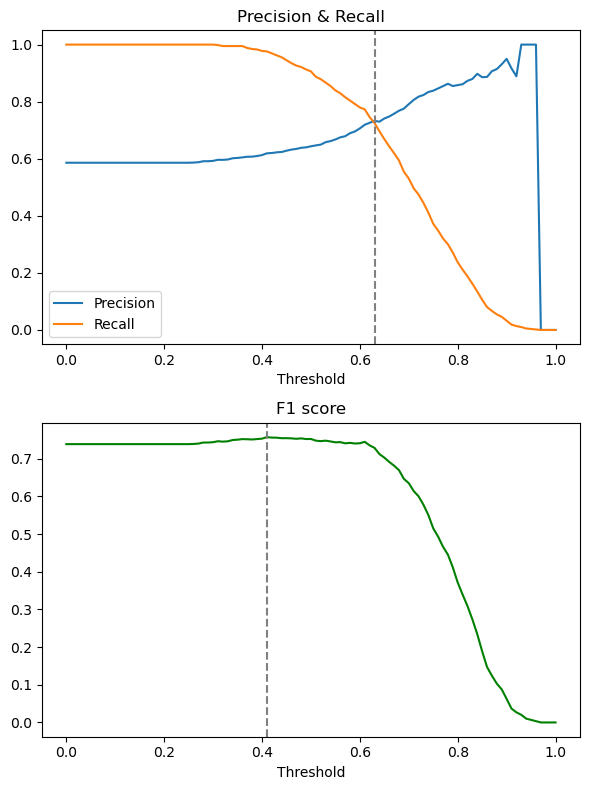

In [108]:
fig, axes = plt.subplots(2, 1, figsize=(6, 8))

axes[0].plot(scores.threshold, scores.precision, label="Precision")
axes[0].plot(scores.threshold, scores.recall, label="Recall")
axes[0].axvline(best_diff.threshold, color="gray", linestyle="--")
axes[0].set_xlabel("Threshold")
axes[0].set_title("Precision & Recall")
axes[0].legend()

axes[1].plot(scores.threshold, scores.f1, color="green")
axes[1].axvline(best.threshold, color="gray", linestyle="--")
axes[1].set_xlabel("Threshold")
axes[1].set_title("F1 score")

plt.tight_layout()
plt.show()

In [112]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)


def cross_validate(C):
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):

        d_tr = df_full_train.iloc[train_idx]
        d_va = df_full_train.iloc[val_idx]

        dv_, m_ = train(d_tr, d_tr[target].values, C=C)
        preds = predict(dv_, m_, d_va)
        
        aucs.append(roc_auc_score(d_va[target].values, preds))
    return np.array(aucs)


scores_c1 = cross_validate(1.0)
print("fold AUCs:", scores_c1.round(4))
print(f"    std = {scores_c1.std():.3f}\n")



fold AUCs: [0.7306 0.7296 0.7363 0.7412 0.7209]
    std = 0.007



In [138]:
results = []
for C in [0.000001, 0.001, 1]:
    s = cross_validate(C)
    results.append((C, round(s.mean(), 3), round(s.std(), 3)))
    print(f"  C={C:<9} mean={s.mean():.3f}  std={s.std():.3f}")

# Best: highest mean, then lowest std, then smallest C
cv_df = pd.DataFrame(
        results, 
        columns = ["c", "mean", "std"]).sort_values("mean", ascending=False
        ).set_index("c")

print(cv_df["mean"].idxmax())

  C=1e-06     mean=0.617  std=0.019
  C=0.001     mean=0.749  std=0.010
  C=1         mean=0.732  std=0.007
0.001
